# Day 3 — Google Play Store Category, Ratings & Size Market Analysis

**Project**: Oasis Infobyte Data Analytics Internship · Task Level 2 (Task 4)  
**Deliverable Focus**: Category Distribution, Market Saturation, Rating Performance & Size-Installs Correlation  

---

### 🎯 Day 3 Core Objectives & Checklist:
- [x] **Category Distribution**: Quantify app concentration across 33 categories; identify saturated giants vs. underserved niche sectors.
- [x] **Ratings Analysis**: Characterize the statistical distribution of user ratings (mean, median, standard deviation, skewness, and interquartile range).
- [x] **Category Rating Comparison**: Aggregate rating benchmarks by sector; isolate categories with top-tier user satisfaction vs. structural dissatisfaction.
- [x] **Size vs. Installs Dynamics**: Formulate and test hypotheses regarding app download volume vs. APK binary size on a logarithmic scale.
- [x] **Correlation Rigor**: Compute and compare parametric (**Pearson $r$**) vs. non-parametric (**Spearman $ho$**) correlation coefficients with p-value significance.
- [x] **Stratified Category Analysis**: Investigate domain-specific size-install dependencies across gaming, shopping, and utility sectors.
- [x] **Production Modularization & Artifacts**: Modular Python routines in `src/category_ratings_analysis.py`, unit test suite in `tests/test_category_ratings.py`, and high-resolution visual exports.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

# Add repository root to path for modular imports
repo_root = Path.cwd().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.category_ratings_analysis import (
    compute_category_distribution,
    compute_rating_statistics,
    compute_category_ratings,
    compute_size_installs_correlation,
    compute_stratified_correlations,
    plot_category_distribution,
    plot_rating_distributions,
    plot_size_vs_installs,
    plot_stratified_correlations
)

print(f"Working Directory: {Path.cwd()}")
print(f"Project Root: {repo_root}")
print("Environment successfully initialized.")


Working Directory: C:\Users\Iba Zaidi\Desktop\OIBSIP\DataAnalytics-L2-GooglePlayStore\Notebooks
Project Root: C:\Users\Iba Zaidi\Desktop\OIBSIP\DataAnalytics-L2-GooglePlayStore
Environment successfully initialized.


## 1. Cleaned Dataset Loading & Verification

We load the pristine dataset `Data/cleaned_googleplaystore.csv` produced during Day 1's data cleaning pipeline (containing 9,659 deduplicated unique apps with standardized numeric types).


In [2]:
data_path = repo_root / 'Data' / 'cleaned_googleplaystore.csv'
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]:,} apps across {df.shape[1]} features")
print("\nFeature Data Types:")
print(df.dtypes)

# Preview first 5 records
df.head(5)


Dataset Shape: 9,659 apps across 15 features

Feature Data Types:
App                    str
Category               str
Rating             float64
Reviews              int64
Size                   str
Installs             int64
Type                   str
Price              float64
Content Rating         str
Genres                 str
Last Updated           str
Current Ver            str
Android Ver            str
Size_MB            float64
Size_MB_Imputed    float64
dtype: object


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB,Size_MB_Imputed
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,10000,Free,0.0,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up,19.0,19.0
1,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,5000000,Free,0.0,Everyone,Art & Design,2018-08-01,1.2.4,4.0.3 and up,8.7,8.7
2,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,50000000,Free,0.0,Teen,Art & Design,2018-06-08,Varies with device,4.2 and up,25.0,25.0
3,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,100000,Free,0.0,Everyone,Art & Design;Creativity,2018-06-20,1.1,4.4 and up,2.8,2.8
4,Paper flowers instructions,ART_AND_DESIGN,4.4,167,5.6M,50000,Free,0.0,Everyone,Art & Design,2017-03-26,1.0,2.3 and up,5.6,5.6


## 2. Category Distribution & Market Saturation Analysis

### Core Analytical Questions:
1. Which app categories dominate the Google Play Store in terms of raw application listings?
2. How concentrated is the app ecosystem across top categories?
3. Where are the niche, underserved sectors that present lower competitive friction?


In [3]:
cat_dist = compute_category_distribution(df)

print("Top 5 Most Saturated Categories:")
display(cat_dist.head(5).style.format({'Percentage': '{:.2f}%', 'Cumulative_Percentage': '{:.2f}%'}))

print("\nTop 5 Niche / Underserved Categories:")
display(cat_dist.tail(5).style.format({'Percentage': '{:.2f}%', 'Cumulative_Percentage': '{:.2f}%'}))


Top 5 Most Saturated Categories:


,Category,App_Count,Percentage,Cumulative_Percentage
0,FAMILY,1874,19.40%,19.40%
1,GAME,946,9.79%,29.20%
2,TOOLS,829,8.58%,37.78%
3,BUSINESS,420,4.35%,42.13%
4,MEDICAL,395,4.09%,46.22%



Top 5 Niche / Underserved Categories:


,Category,App_Count,Percentage,Cumulative_Percentage
28,EVENTS,64,0.66%,97.62%
29,ART_AND_DESIGN,61,0.63%,98.25%
30,PARENTING,60,0.62%,98.87%
31,COMICS,56,0.58%,99.45%
32,BEAUTY,53,0.55%,100.00%


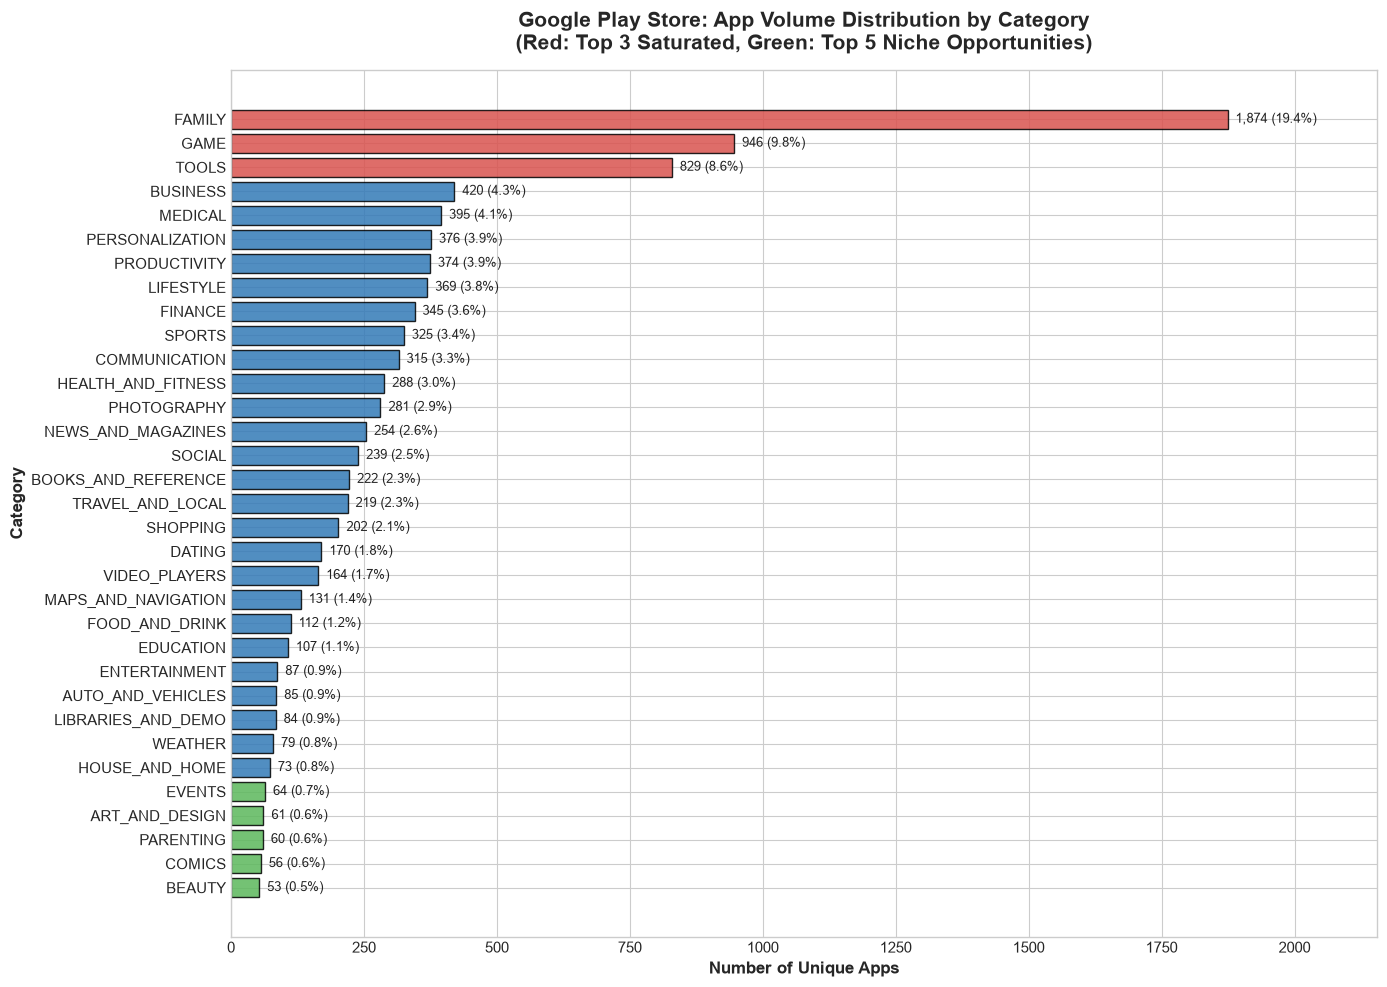

In [4]:
fig1 = plot_category_distribution(df)
plt.show()


### 📊 Key Category Insights:

1. **Massive Concentration in the Top 3**:
   - `FAMILY` (1,874 apps / **19.40%**), `GAME` (946 apps / **9.79%**), and `TOOLS` (829 apps / **8.58%**) constitute **37.78%** of the entire Google Play Store catalog.
   - Adding `BUSINESS` (4.35%) and `MEDICAL` (4.09%) means the top 5 categories command nearly half (**46.22%**) of all published apps.
2. **Niche & Low-Saturation Sectors**:
   - `BEAUTY` (53 apps / 0.55%), `COMICS` (56 apps / 0.58%), `PARENTING` (60 apps / 0.62%), `ART_AND_DESIGN` (61 apps / 0.63%), and `EVENTS` (64 apps / 0.66%) have minimal app counts.
   - For an independent developer or startup, entering a niche category offers substantially lower App Store Optimization (ASO) keyword bidding costs and higher organic discoverability compared to the hyper-saturated `FAMILY` or `GAME` verticals.


## 3. Ratings Distribution & Cross-Category Evaluation

### Core Analytical Questions:
1. What is the baseline rating expected by users across the ecosystem?
2. Is the rating distribution Gaussian (normal), or does it suffer from severe left-skewed rating inflation?
3. Which categories achieve the highest customer satisfaction, and which face persistent dissatisfaction?


In [5]:
rating_stats = compute_rating_statistics(df)

stats_summary = pd.DataFrame([{
    "Metric": "Total Catalog Size", "Value": f"{rating_stats['total_apps']:,}"
}, {
    "Metric": "Rated Apps Count", "Value": f"{rating_stats['rated_apps']:,} ({rating_stats['rated_percentage']:.1f}%)"
}, {
    "Metric": "Unrated Apps Count", "Value": f"{rating_stats['unrated_apps']:,} ({100 - rating_stats['rated_percentage']:.1f}%)"
}, {
    "Metric": "Mean Rating", "Value": f"{rating_stats['mean']:.3f}"
}, {
    "Metric": "Median Rating", "Value": f"{rating_stats['median']:.3f}"
}, {
    "Metric": "Standard Deviation", "Value": f"{rating_stats['std']:.3f}"
}, {
    "Metric": "Interquartile Range (IQR)", "Value": f"[{rating_stats['q25']:.2f}, {rating_stats['q75']:.2f}] (Δ = {rating_stats['iqr']:.2f})"
}, {
    "Metric": "Skewness", "Value": f"{rating_stats['skewness']:.3f} (Strong Left Skew)"
}, {
    "Metric": "Kurtosis", "Value": f"{rating_stats['kurtosis']:.3f} (Leptokurtic Peak)"
}])

display(stats_summary)


,Metric,Value
0,Total Catalog Size,"9,659"
1,Rated Apps Count,"8,196 (84.9%)"
2,Unrated Apps Count,"1,463 (15.1%)"
3,Mean Rating,4.173
4,Median Rating,4.300
5,Standard Deviation,0.536
6,Interquartile Range (IQR),"[4.00, 4.50] (Δ = 0.50)"
7,Skewness,-1.745 (Strong Left Skew)
8,Kurtosis,5.134 (Leptokurtic Peak)


In [6]:
cat_ratings = compute_category_ratings(df)

print("Top 5 Highest-Rated Categories:")
display(cat_ratings.head(5).style.format({
    'Mean_Rating': '{:.3f}', 'Median_Rating': '{:.2f}', 'Std_Rating': '{:.3f}', 
    'IQR_Rating': '{:.2f}', 'Coverage_Pct': '{:.1f}%'
}))

print("\nBottom 5 Lowest-Rated Categories:")
display(cat_ratings.tail(5).style.format({
    'Mean_Rating': '{:.3f}', 'Median_Rating': '{:.2f}', 'Std_Rating': '{:.3f}', 
    'IQR_Rating': '{:.2f}', 'Coverage_Pct': '{:.1f}%'
}))


Top 5 Highest-Rated Categories:


,Category,Rated_Count,Mean_Rating,Median_Rating,Std_Rating,Min_Rating,Max_Rating,IQR_Rating,Total_Apps,Coverage_Pct
0,EVENTS,45,4.436,4.50,0.419,2.900000,5.000000,0.50,64,70.3%
1,ART_AND_DESIGN,59,4.359,4.40,0.360,3.200000,5.000000,0.60,61,96.7%
2,EDUCATION,106,4.355,4.40,0.268,3.500000,4.900000,0.40,107,99.1%
3,BOOKS_AND_REFERENCE,169,4.345,4.50,0.438,2.700000,5.000000,0.50,222,76.1%
4,PERSONALIZATION,298,4.332,4.40,0.359,2.500000,5.000000,0.40,376,79.3%



Bottom 5 Lowest-Rated Categories:


,Category,Rated_Count,Mean_Rating,Median_Rating,Std_Rating,Min_Rating,Max_Rating,IQR_Rating,Total_Apps,Coverage_Pct
28,TRAVEL_AND_LOCAL,187,4.070,4.20,0.532,2.200000,5.000000,0.60,219,85.4%
29,VIDEO_PLAYERS,149,4.045,4.20,0.562,1.800000,4.900000,0.60,164,90.9%
30,TOOLS,720,4.040,4.20,0.619,1.000000,5.000000,0.60,829,86.9%
31,MAPS_AND_NAVIGATION,118,4.036,4.20,0.527,1.900000,4.900000,0.70,131,90.1%
32,DATING,133,3.980,4.10,0.629,1.000000,5.000000,0.80,170,78.2%


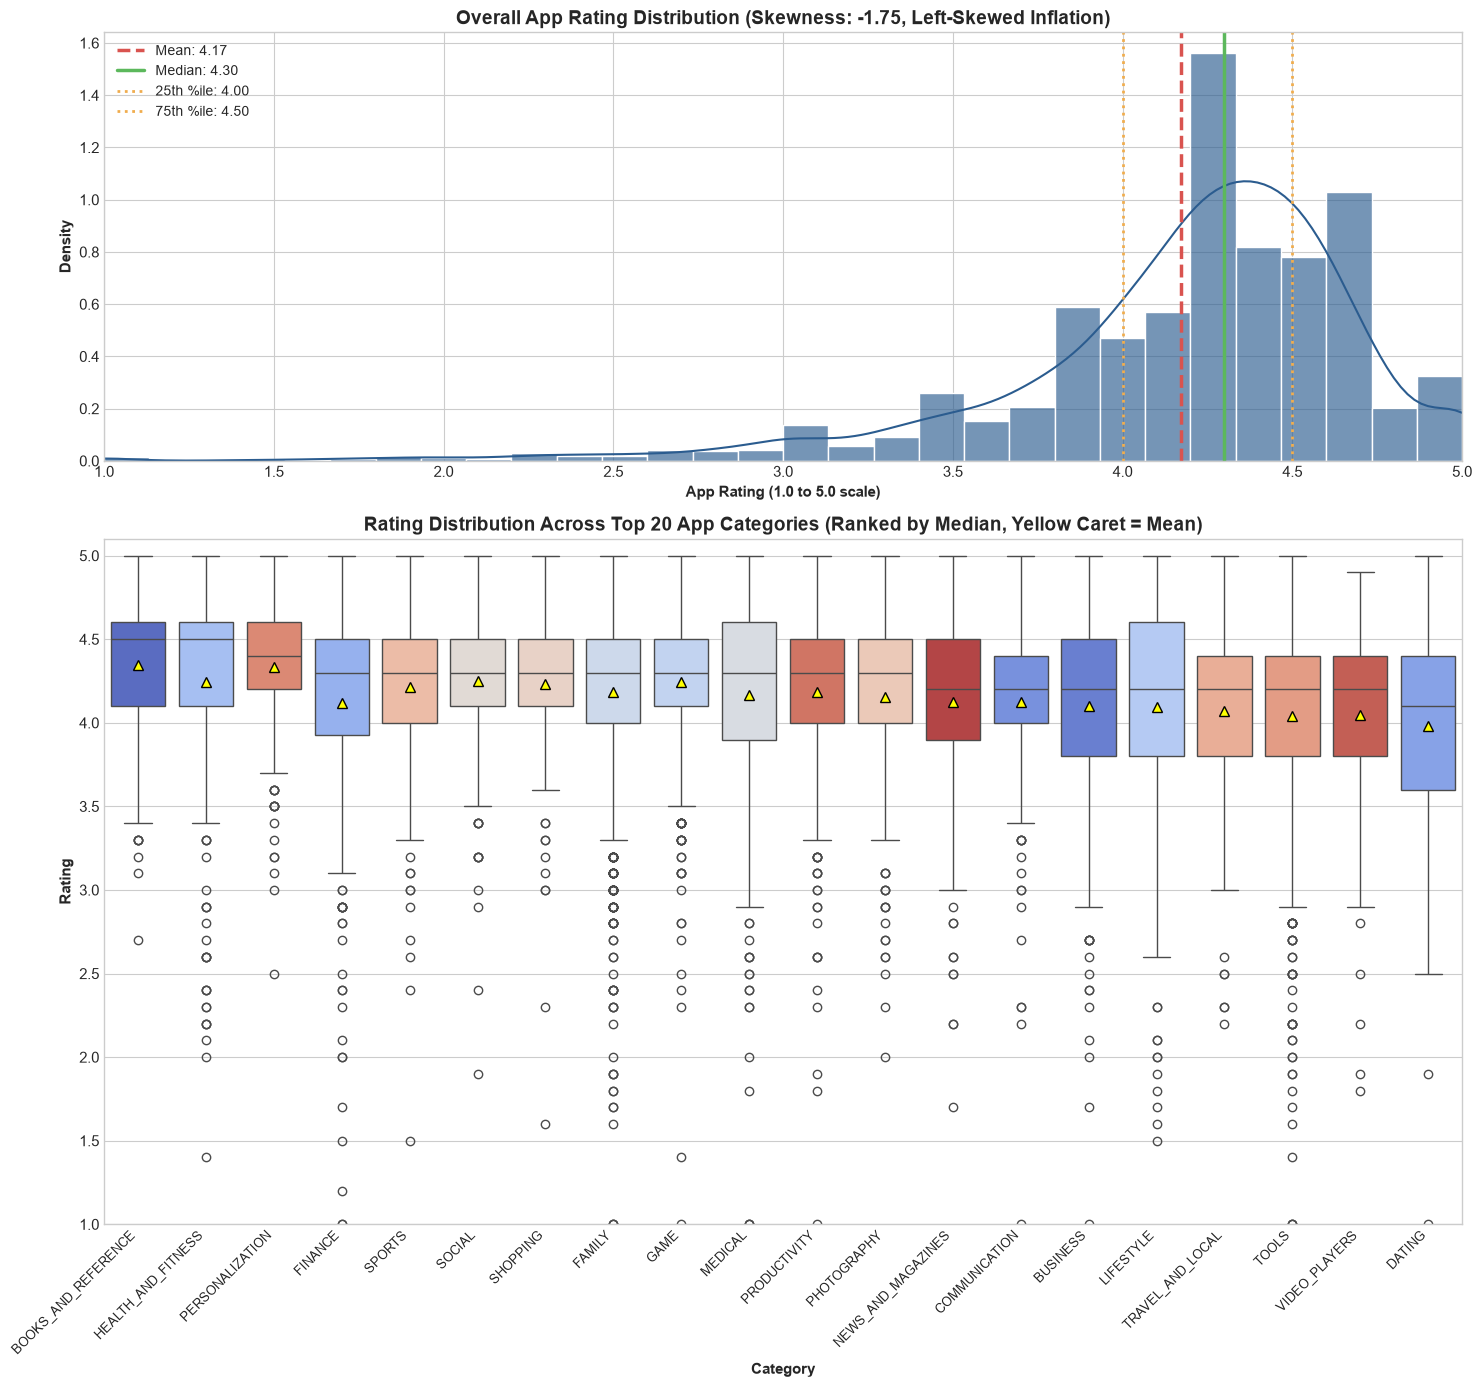

In [7]:
fig2 = plot_rating_distributions(df)
plt.show()


### 📊 Key Rating Insights:

1. **Systemic Left-Skewed Rating Inflation**:
   - Mean rating is **4.173** and median rating is **4.300**, with a skewness of **-1.745**.
   - 75% of rated apps score above **4.00**, meaning that in mobile marketplace psychology, a rating below 4.0 is perceived by consumers as substandard or defective.
2. **Category Satisfaction Leaders**:
   - `EVENTS` (Mean: **4.436**, Median: 4.5) and `ART_AND_DESIGN` (Mean: **4.359**, Median: 4.4) achieve the highest user ratings.
   - `EDUCATION` maintains the lowest dispersion ($\sigma = 0.268$), indicating uniformly dependable app quality and aligned user expectations.
3. **Category Satisfaction Laggards**:
   - `DATING` is the **only category with a mean rating under 4.0** (Mean: **3.980**, Median: 4.1, $\sigma = 0.629$). High churn, algorithmic matchmaking expectations, and aggressive paywalls drive severe user frustration.
   - `TOOLS` (Mean: **4.040**, $\sigma = 0.619$) exhibits wide variance: high utility apps score 4.8+, while buggy ad-supported utilities are punished with 1.0–2.5 star reviews.


## 4. App Size vs. Number of Installs Correlation Analysis

### Hypothesis Testing:
- **Null Hypothesis ($H_0$)**: There is no relationship or a negative relationship between an app's binary size (MB) and its total installation volume (users avoid large downloads).
- **Alternative Hypothesis ($H_1$)**: There is a positive correlation between app size and installation count (successful apps scale features, assets, and functionality).


In [8]:
corr_explicit = compute_size_installs_correlation(df, use_imputed=False)
corr_imputed = compute_size_installs_correlation(df, use_imputed=True)

corr_comparison = pd.DataFrame([
    {
        "Dataset Subset": "Explicit Size Records (n=8,431)",
        "Pearson r (Linear)": f"{corr_explicit['pearson_r']:.4f}",
        "Pearson p-value": f"{corr_explicit['pearson_p']:.2e}",
        "Spearman ρ (Rank)": f"{corr_explicit['spearman_rho']:.4f}",
        "Spearman p-value": f"{corr_explicit['spearman_p']:.2e}",
        "Pearson r with log10(Installs)": f"{corr_explicit['pearson_log_r']:.4f}"
    },
    {
        "Dataset Subset": "All Apps with Category Imputation (n=9,659)",
        "Pearson r (Linear)": f"{corr_imputed['pearson_r']:.4f}",
        "Pearson p-value": f"{corr_imputed['pearson_p']:.2e}",
        "Spearman ρ (Rank)": f"{corr_imputed['spearman_rho']:.4f}",
        "Spearman p-value": f"{corr_imputed['spearman_p']:.2e}",
        "Pearson r with log10(Installs)": f"{corr_imputed['pearson_log_r']:.4f}"
    }
])

display(corr_comparison)


,Dataset Subset,Pearson r (Linear),Pearson p-value,Spearman ρ (Rank),Spearman p-value,Pearson r with log10(Installs)
0,"Explicit Size Records (n=8,431)",0.1342,3.46e-35,0.3101,2.13e-187,0.2998
1,"All Apps with Category Imputation (n=9,659)",0.0233,2.20e-02,0.2674,9.25e-158,0.2309


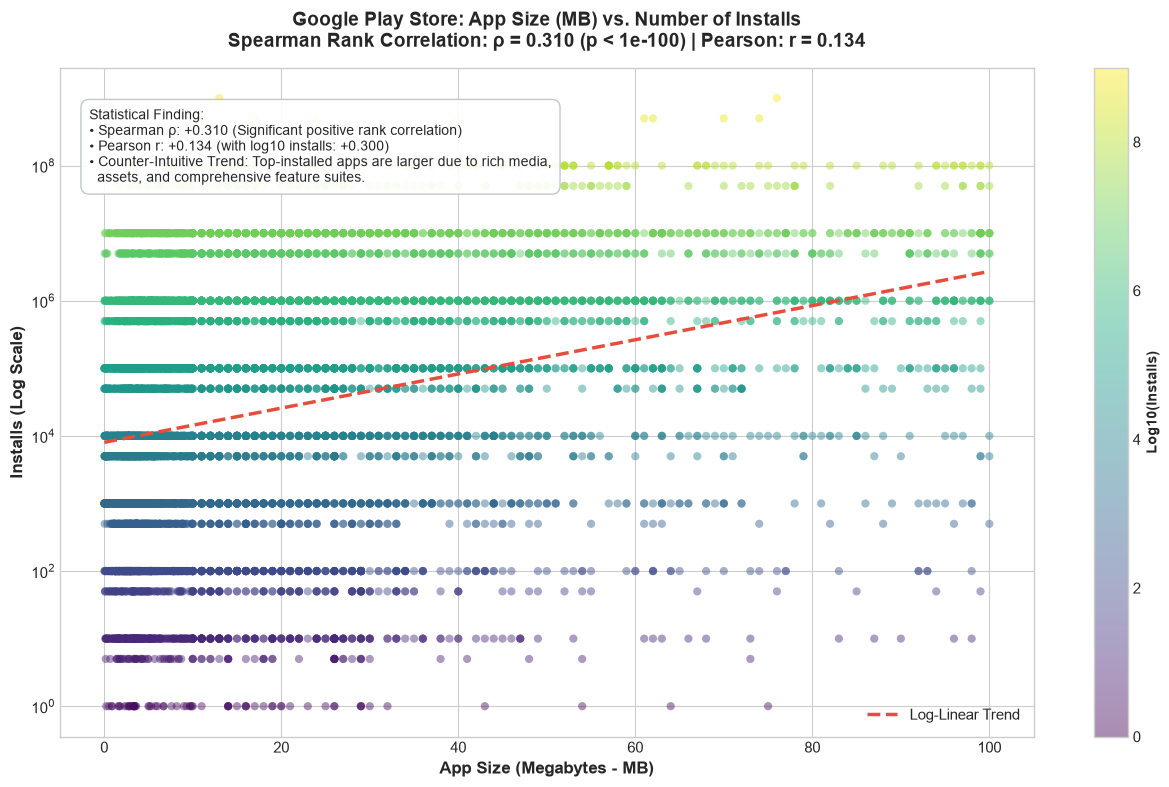

In [9]:
fig3 = plot_size_vs_installs(df)
plt.show()


## 5. Stratified Correlation Analysis by App Category

Does the size-vs-installs relationship hold uniformly, or do games, utilities, and commercial platforms follow different dynamics?


In [10]:
strat_df = compute_stratified_correlations(df, min_apps=30)

print(f"Stratified Analysis across {len(strat_df)} Categories (n >= 30 apps):")
display(strat_df.head(10).style.format({
    'Pearson_r': '{:.3f}', 'Pearson_p': '{:.2e}', 'Spearman_rho': '{:.3f}', 
    'Spearman_p': '{:.2e}', 'Median_Size_MB': '{:.1f} MB', 'Median_Installs': '{:,.0f}'
}))


Stratified Analysis across 33 Categories (n >= 30 apps):


,Category,Sample_Size,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,Median_Size_MB,Median_Installs
0,SHOPPING,168,0.193,1.22e-02,0.578,2.35e-16,12.0 MB,"500,000"
1,ART_AND_DESIGN,59,0.304,1.93e-02,0.552,5.74e-06,8.7 MB,"100,000"
2,PHOTOGRAPHY,222,0.392,1.50e-09,0.459,5.81e-13,9.6 MB,"1,000,000"
3,FAMILY,1755,0.226,7.94e-22,0.450,4.22e-88,19.0 MB,"50,000"
4,FOOD_AND_DRINK,88,0.241,2.40e-02,0.417,5.24e-05,17.0 MB,"100,000"
5,BEAUTY,47,0.138,3.55e-01,0.412,4.03e-03,9.2 MB,"50,000"
6,FINANCE,299,0.283,6.38e-07,0.407,2.25e-13,12.0 MB,"10,000"
7,GAME,862,0.151,8.30e-06,0.349,4.23e-26,37.0 MB,"1,000,000"
8,SPORTS,285,0.161,6.32e-03,0.343,2.83e-09,20.0 MB,"50,000"
9,DATING,158,0.145,6.96e-02,0.318,4.76e-05,11.0 MB,"10,000"


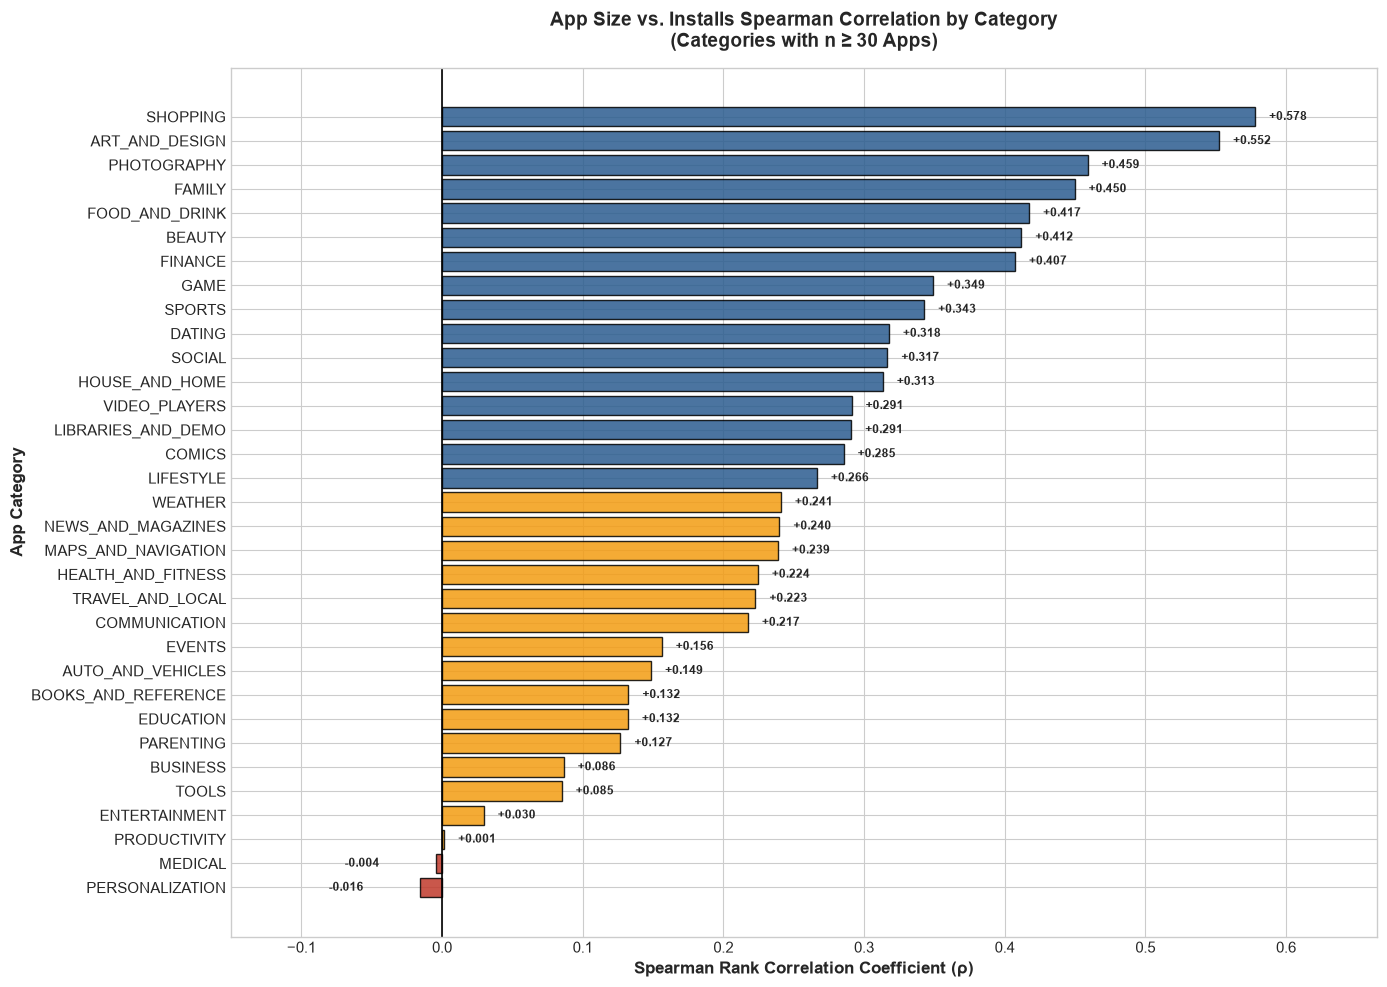

In [11]:
fig4 = plot_stratified_correlations(strat_df)
plt.show()


## 6. Synthesis & Strategic Takeaways for Android Developers

### 1. Market Entry & Competitive Saturation
- **Do not enter `FAMILY`, `GAME`, or `TOOLS` without deep capitalization**: These three categories account for **37.8%** of the store. Competing organically against incumbent apps with 10M+ installs is prohibitively expensive.
- **Capitalize on high-satisfaction niche categories**: `ART_AND_DESIGN`, `EVENTS`, and `EDUCATION` display high average ratings (> 4.35) and low listing volume (< 110 apps), creating prime opportunities for focused, high-utility apps.

### 2. Rating Thresholds as Retention KPIs
- **4.0 Stars is the survival threshold**: With a market median rating of **4.30** and 75% of apps scoring $\ge 4.0$, any app scoring $< 4.0$ will experience significant algorithmic penalty in Play Store search ranking and high conversion drop-off.
- **Pay special attention to UX in high-friction verticals**: `DATING` (mean rating: 3.98) and `TOOLS` suffer from extreme user criticism. Developers entering these domains must prioritize crash-free rates, transparent pricing, and minimal disruptive advertising.

### 3. The "Feature Richness" Paradox in App Size
- **Do not artificially cripple app features to minimize APK size**: Spearman rank correlation is statistically positive (**$\rho = +0.3101$, $p = 2.13 \times 10^{-187}$**). High-install apps are systematically larger because users reward rich UI animations, native offline assets, and comprehensive capabilities.
- **Category nuance is critical**: In `SHOPPING` ($\rho = 0.578$) and `GAME` ($\rho = 0.349$), size scales directly with success. However, in `TOOLS` ($\rho = 0.085$) and `PRODUCTIVITY` ($\rho = 0.001$), size has zero correlation with install success — utility users demand lean, instant-launch tools.

---
**Day 3 Deliverable Status**: Completed & verified against Task 4 technical requirements.
